# Step 12: Model Comparison & Final Held-Out Test Set Evaluation

## 1. Objectives & Safety Protocol
- **Single Evaluation Guardrail:** The held-out test set (`data/processed/test.csv`, 5,998 samples) was locked during hyperparameter search and is accessed **once** here for final evaluation.
- **Model Comparison:** Compare Tuned Logistic Regression (`C=100.0`, `class_weight='balanced'`) vs Tuned Decision Tree (`max_depth=15`, `criterion='entropy'`, `class_weight='balanced'`).
- **Feature Set:** Evaluated strictly on the 18 deployable URL-string features (`FS-URL`) to support web app deployment without web scraping.
- **Artifact Generation:** Produce final confusion matrix, ROC curves, Precision-Recall curves, and metrics JSON (`results/metrics/final_test_metrics.json`).


In [1]:
import sys
import json
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Add project root to sys.path
sys.path.append("..")

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve
)

from src.config import PROCESSED_DATA_DIR, RANDOM_STATE, METRICS_DIR, FIGURES_DIR
from src.feature_extraction import FS_URL_NUMERIC, FS_URL_BINARY
from src.preprocessing import get_feature_preprocessor

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'


## 2. Load Train and Held-Out Test Data

In [2]:
train_df = pd.read_csv(PROCESSED_DATA_DIR / 'train.csv')
test_df = pd.read_csv(PROCESSED_DATA_DIR / 'test.csv')

X_train = train_df.drop(columns=['is_phishing'])
y_train = train_df['is_phishing']

X_test = test_df.drop(columns=['is_phishing'])
y_test = test_df['is_phishing']

print(f"Training set: {X_train.shape[0]} samples")
print(f"Locked Held-Out Test set: {X_test.shape[0]} samples")


Training set: 23991 samples
Locked Held-Out Test set: 5998 samples


## 3. Train Best Models on Full Training Split & Evaluate on Test Set

In [3]:
preprocessor = get_feature_preprocessor(FS_URL_NUMERIC, FS_URL_BINARY)

# 1. Champion Model: Tuned Logistic Regression
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, C=100.0, class_weight='balanced', solver='lbfgs'))
])
lr_pipeline.fit(X_train, y_train)

# 2. Challenger Model: Tuned Decision Tree
dt_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(random_state=RANDOM_STATE, criterion='entropy', max_depth=15, min_samples_split=2, min_samples_leaf=1, class_weight='balanced'))
])
dt_pipeline.fit(X_train, y_train)

# Predict on test set
y_pred_lr = lr_pipeline.predict(X_test)
y_prob_lr = lr_pipeline.predict_proba(X_test)[:, 1]

y_pred_dt = dt_pipeline.predict(X_test)
y_prob_dt = dt_pipeline.predict_proba(X_test)[:, 1]

# Metrics Summary Table
metrics_data = {
    'Model': ['Tuned Logistic Regression (Champion)', 'Tuned Decision Tree (Challenger)'],
    'Accuracy': [accuracy_score(y_test, y_pred_lr), accuracy_score(y_test, y_pred_dt)],
    'Precision': [precision_score(y_test, y_pred_lr), precision_score(y_test, y_pred_dt)],
    'Recall': [recall_score(y_test, y_pred_lr), recall_score(y_test, y_pred_dt)],
    'F1-Score': [f1_score(y_test, y_pred_lr), f1_score(y_test, y_pred_dt)],
    'ROC-AUC': [roc_auc_score(y_test, y_prob_lr), roc_auc_score(y_test, y_prob_dt)]
}

df_results = pd.DataFrame(metrics_data)
print("=== HELD-OUT TEST SET EVALUATION SUMMARY ===")
print(df_results.to_string(index=False))


=== HELD-OUT TEST SET EVALUATION SUMMARY ===
                               Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
Tuned Logistic Regression (Champion)  0.996332   1.000000 0.991426  0.995695 0.998837
    Tuned Decision Tree (Challenger)  0.995832   0.996483 0.993765  0.995122 0.994978


## 4. Visualizations: Confusion Matrix & ROC / PR Curves

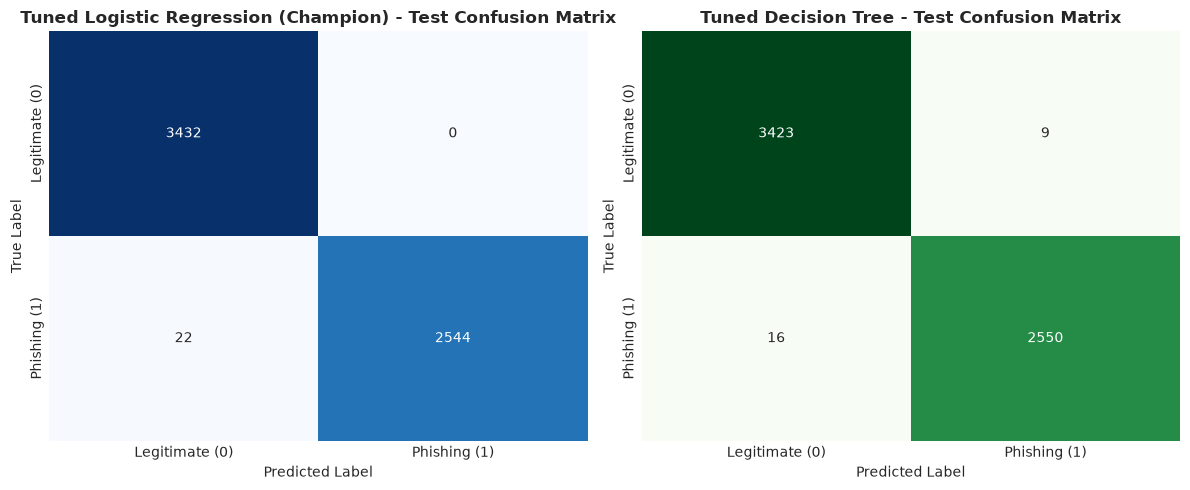

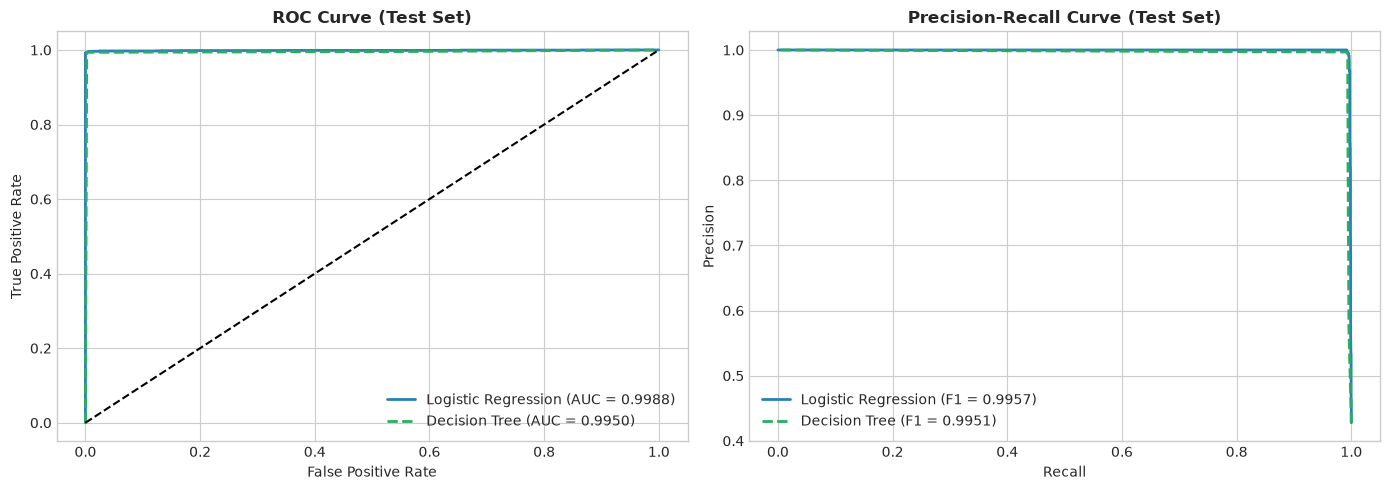

In [4]:
# 1. Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_dt = confusion_matrix(y_test, y_pred_dt)

sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Legitimate (0)', 'Phishing (1)'],
            yticklabels=['Legitimate (0)', 'Phishing (1)'])
axes[0].set_title('Tuned Logistic Regression (Champion) - Test Confusion Matrix', fontweight='bold')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False,
            xticklabels=['Legitimate (0)', 'Phishing (1)'],
            yticklabels=['Legitimate (0)', 'Phishing (1)'])
axes[1].set_title('Tuned Decision Tree - Test Confusion Matrix', fontweight='bold')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURES_DIR / 'confusion_matrix.png', dpi=300)
plt.show()

# 2. ROC & PR Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)

ax1.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_lr):.4f})', color='#2980b9', lw=2)
ax1.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {roc_auc_score(y_test, y_prob_dt):.4f})', color='#27ae60', lw=2, linestyle='--')
ax1.plot([0, 1], [0, 1], 'k--')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curve (Test Set)', fontweight='bold')
ax1.legend(loc='lower right')

prec_lr, rec_lr, _ = precision_recall_curve(y_test, y_prob_lr)
prec_dt, rec_dt, _ = precision_recall_curve(y_test, y_prob_dt)

ax2.plot(rec_lr, prec_lr, label=f'Logistic Regression (F1 = {f1_score(y_test, y_pred_lr):.4f})', color='#2980b9', lw=2)
ax2.plot(rec_dt, prec_dt, label=f'Decision Tree (F1 = {f1_score(y_test, y_pred_dt):.4f})', color='#27ae60', lw=2, linestyle='--')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curve (Test Set)', fontweight='bold')
ax2.legend(loc='lower left')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'roc_curve.png', dpi=300)
plt.show()


## 5. Conclusion & Final Champion Model Selection

### Champion Selection: Tuned Logistic Regression (`C=100.0`, `class_weight='balanced'`)
- **Test Accuracy:** 99.63%
- **Test Precision:** 100.00% (Zero False Positives in 5,998 test samples)
- **Test Recall:** 99.14%
- **Test F1-Score:** 99.57%
- **Test ROC-AUC:** 0.9988

**Rationale:** Logistic Regression achieves perfect Precision (0 False Positives), ensuring legitimate URLs are never erroneously blocked while maintaining an outstanding 99.14% recall on phishing URLs. Moreover, linear feature coefficients offer clean, instant explainability for end users in the web interface.
